<a href="https://colab.research.google.com/github/Niveditha1176/Credit-gating-on-tabular-foundation-models-/blob/main/run_on_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Credit gating on tabular foundation models : TablCLv2 and TabPFN



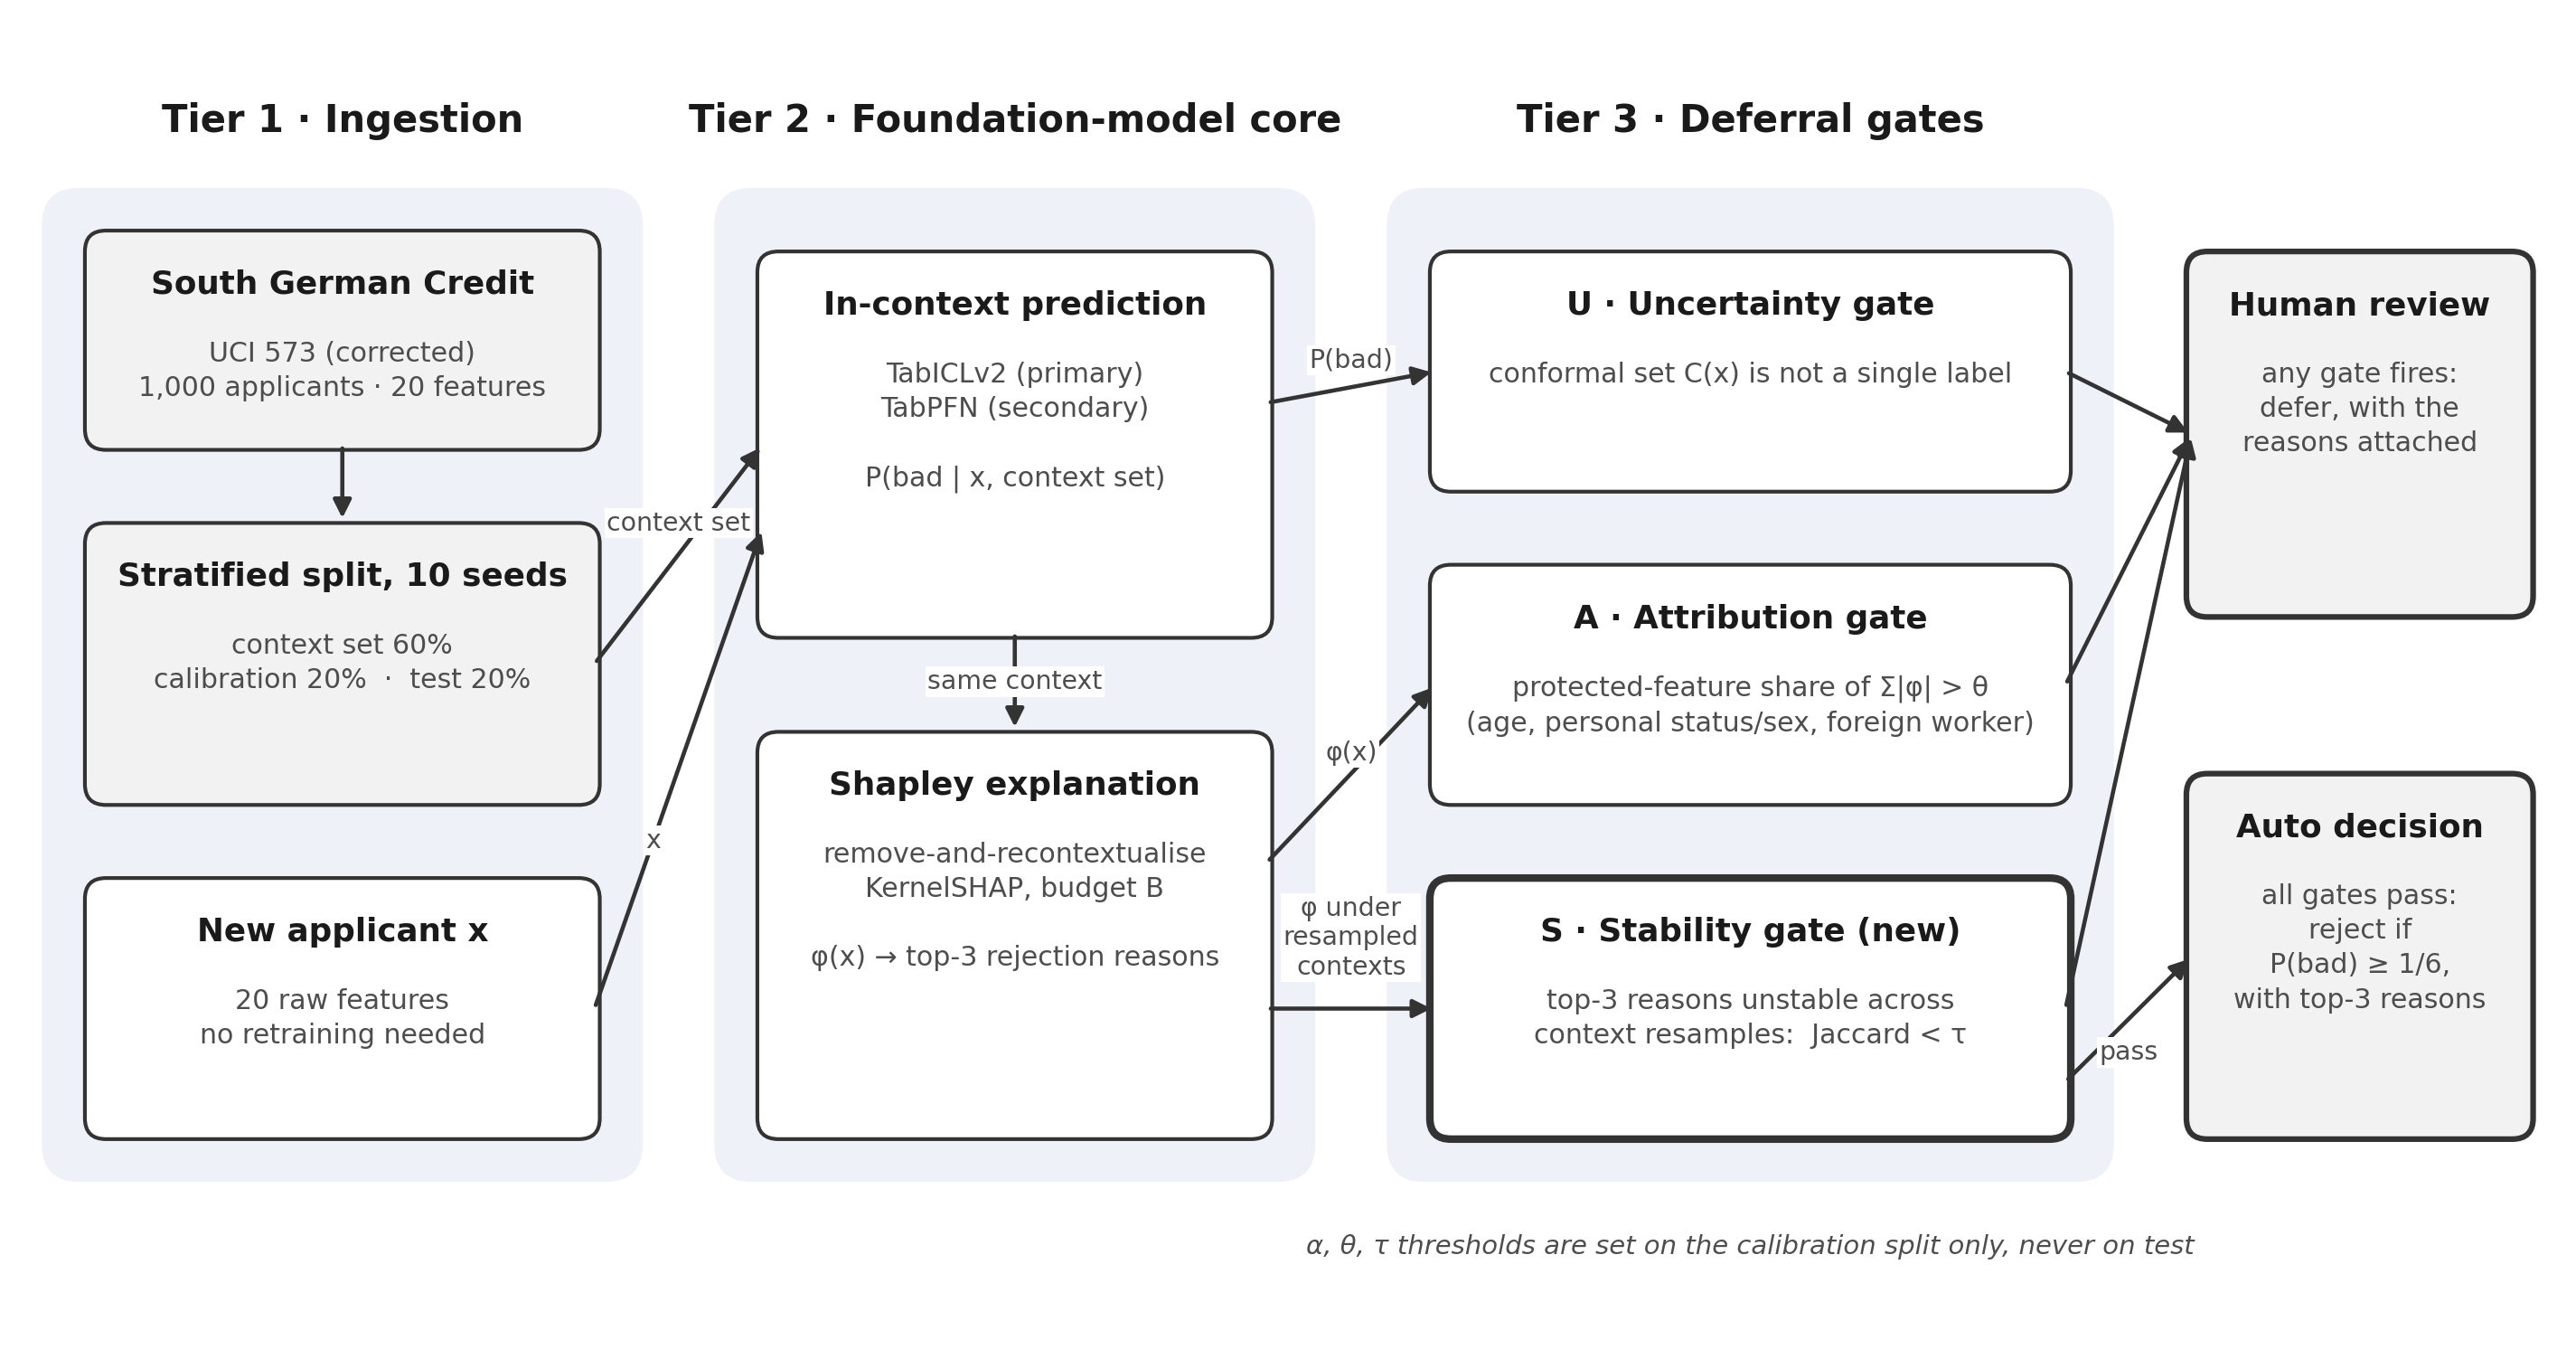

saved /content/drive/MyDrive/credit-tfm-figures/fig_architecture.pdf


In [ ]:
# ===== Fig. 1 architecture diagram =====


import os
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import Image, display
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch

F = Path(os.environ.get("FIGURES_DIR", "/content/drive/MyDrive/credit-tfm-figures"))
F.mkdir(parents=True, exist_ok=True)
INK, MUTED, LINE = "#1a1a1a", "#4d4d4d", "#333333"
TIER, BOX, OUT = "#eef1f8", "#ffffff", "#f2f2f2"
plt.rcParams.update({"font.family": "DejaVu Sans"})

fig, ax = plt.subplots(figsize=(12, 6.2))
ax.set_xlim(0, 120); ax.set_ylim(0, 62); ax.axis("off")


def box(x, y, w, h, title, body="", fc=BOX, lw=1.0):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.25,rounding_size=1.0",
                                fc=fc, ec=LINE, lw=lw))
    ax.text(x + w / 2, y + h - 1.6, title, ha="center", va="top", fontsize=8.6,
            fontweight="bold", color=INK)
    if body:
        ax.text(x + w / 2, y + h - 5.0, body, ha="center", va="top", fontsize=7.2,
                color=MUTED, linespacing=1.4)
    return (x, y, w, h)


def arrow(p, q, label=None, at=0.5, dy=0.0, rad=0.0, ls="-"):
    ax.add_patch(FancyArrowPatch(p, q, arrowstyle="-|>", mutation_scale=10, lw=1.1, color=LINE,
                                 ls=ls, connectionstyle=f"arc3,rad={rad}", shrinkA=1, shrinkB=1))
    if label:
        x = p[0] + (q[0] - p[0]) * at
        y = p[1] + (q[1] - p[1]) * at + dy
        ax.text(x, y, label, ha="center", va="center", fontsize=6.8, color=MUTED,
                bbox=dict(fc="white", ec="none", pad=0.6))


# tier panels + headers
for x0, w, title in [(1, 28, "Tier 1 · Ingestion"), (33, 28, "Tier 2 · Foundation-model core"),
                     (65, 34, "Tier 3 · Deferral gates")]:
    ax.add_patch(FancyBboxPatch((x0, 7), w, 47, boxstyle="round,pad=0.3,rounding_size=1.8",
                                fc=TIER, ec="none"))
    ax.text(x0 + w / 2, 57.5, title, ha="center", va="center", fontsize=10, fontweight="bold",
            color=INK)

# Tier 1
box(3, 42, 24, 10, "South German Credit", "UCI 573 (corrected)\n1,000 applicants · 20 features", OUT)
box(3, 25, 24, 13, "Stratified split, 10 seeds", "context set 60%\ncalibration 20%  ·  test 20%", OUT)
box(3, 9, 24, 12, "New applicant x", "20 raw features\nno retraining needed")
arrow((15, 42), (15, 38.3))

# Tier 2
box(35, 33, 24, 18, "In-context prediction",
    "TabICLv2 (primary)\nTabPFN (secondary)\n\nP(bad | x, context set)")
box(35, 9, 24, 19, "Shapley explanation",
    "remove-and-recontextualise\nKernelSHAP, budget B\n\nφ(x) → top-3 rejection reasons")
arrow((27, 31.5), (35, 42), "context set", at=0.5, dy=1.5)
arrow((27, 15), (35, 38), "x", at=0.35, dy=0)
arrow((47, 33), (47, 28.3), "same context", at=0.5)

# Tier 3
box(67, 40, 30, 11, "U · Uncertainty gate", "conformal set C(x) is not a single label")
box(67, 25, 30, 11, "A · Attribution gate", "protected-feature share of Σ|φ| > θ\n(age, personal status/sex, foreign worker)")
box(67, 9, 30, 12, "S · Stability gate (new)", "top-3 reasons unstable across\ncontext resamples:  Jaccard < τ", lw=2.0)
ax.text(82, 3.6, "α, θ, τ thresholds are set on the calibration split only, never on test",
        ha="center", va="center", fontsize=7, color=MUTED, style="italic")
arrow((59, 44), (67, 45.5), "P(bad)", at=0.5, dy=1.3)
arrow((59, 22), (67, 30.5), "φ(x)", at=0.5, dy=1.0)
arrow((59, 15), (67, 15), "φ under\nresampled\ncontexts", at=0.5, dy=3.4)

# outcomes
box(103, 34, 16, 17, "Human review", "any gate fires:\ndefer, with the\nreasons attached", OUT, lw=1.5)
box(103, 9, 16, 17, "Auto decision", "all gates pass:\nreject if\nP(bad) ≥ 1/6,\nwith top-3 reasons", OUT, lw=1.5)
for y in (45.5, 30.5, 15):
    arrow((97, y), (103, 42.5))
arrow((97, 11.5), (103, 17.5), "pass", at=0.5, dy=-1.6)

for ext in ("png", "pdf"):
    fig.savefig(F / f"fig_architecture.{ext}", dpi=300, bbox_inches="tight")
plt.close(fig)
display(Image(filename=str(F / "fig_architecture.png"), width=1000))   # shows it here in Colab
print("saved", F / "fig_architecture.pdf")

In [ ]:
import os,shutil
if os.path.ismount('/content/drive'):
  print('Drive is already connected - nothing to clean')
else:
  shutil.rmtree('/content/drive',ignore_errors=True)
  print('removed the temporary loacal folder , Now run the cell below to mount the drive')

removed the temporary loacal folder , Now run the cell below to mount the drive


In [ ]:
# 1. Mount Drive and copy the code from My Drive/credit-tfm/credit-tfm
from google.colab import drive
drive.mount('/content/drive')
import os, pathlib, shutil

DRIVE = pathlib.Path('/content/drive/MyDrive')
SOURCE = DRIVE / 'credit-tfm' / 'credit-tfm'
CODE = pathlib.Path('/content/credit-tfm')

if not CODE.exists():
    shutil.copytree(SOURCE, CODE)

os.chdir(CODE)
os.environ['RESULTS_DIR'] = str(DRIVE / 'credit-tfm-results')
os.environ['FIGURES_DIR'] = str(DRIVE / 'credit-tfm-figures')
print('Working in', os.getcwd())
print(sorted(os.listdir()))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Working in /content/credit-tfm
['README.md', 'configs', 'experiments', 'notebooks', 'requirements.txt', 'src', 'tests']


In [ ]:
!pip install -q -r requirements.txt

In [ ]:
# 3. TabPFN licence token
from google.colab import userdata
os.environ['TABPFN_TOKEN'] = userdata.get('TABPFN_TOKEN')
os.environ['TABPFN_NO_BROWSER'] = '1'
import torch; print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'NONE - switch the runtime to GPU')

GPU: Tesla T4


In [ ]:
# 4. Tests: Shapley maths, conformal coverage, and a full mini-pipeline on synthetic data
!python tests/test_core.py

ok test_kernelshap_exact_when_enumerated
ok test_kernelshap_converges
ok test_conformal_coverage
13:15:04 E1 seed 0 logreg
13:15:04 E1 seed 0 rf_paper1
13:15:05 E1 seed 0 stub_fm
13:15:05 E1 seed 1 logreg
13:15:05 E1 seed 1 rf_paper1
13:15:06 E1 seed 1 stub_fm
                 roc_auc         pr_auc          brier            ece       exp_cost          error  fit_predict_s  n_seeds
model                                                                                                                      
rf_paper1  0.644 ± 0.053  0.485 ± 0.061  0.212 ± 0.010  0.046 ± 0.012  0.693 ± 0.095  0.643 ± 0.025  0.616 ± 0.009        2
stub_fm    0.637 ± 0.007  0.494 ± 0.003  0.215 ± 0.003  0.064 ± 0.011  0.777 ± 0.088  0.597 ± 0.004  0.004 ± 0.000        2
logreg     0.610 ± 0.042  0.484 ± 0.077  0.224 ± 0.016  0.105 ± 0.018  0.840 ± 0.007  0.590 ± 0.021  0.034 ± 0.012        2
    model    method  alpha  coverage_mean  deferral_rate_mean  auto_error_mean  auto_exp_cost_mean
   logreg conformal 

In [ ]:
# 5. Data: download South German Credit and check group sizes.
!python -m src.data

[data] ucimlrepo failed ("South German Credit" dataset (id=573) exists in the repository, but is not avai); falling back to the UCI zip
south_german (1000, 20) bad rate 0.3
age_band {np.str_('25plus'): np.int64(850), np.str_('under25'): np.int64(150)}
foreign_worker {'1': np.int64(37), '2': np.int64(963)}
personal_status_sex {'1': np.int64(50), '2': np.int64(310), '3': np.int64(548), '4': np.int64(92)}


##(E1 pilot, seed 0). It's the first run with TabICL and TabPFN

In [ ]:
# E1 — Benchmark (RQ1).  Tuning 4 tree models x 50 trials
!python experiments/run_e1.py --seeds 0

                 roc_auc         pr_auc          brier            ece       exp_cost          error  fit_predict_s  n_seeds
model                                                                                                                      
tabicl       0.809 ± nan    0.683 ± nan    0.154 ± nan    0.031 ± nan    0.545 ± nan    0.405 ± nan    5.919 ± nan        1
tabpfn       0.808 ± nan    0.711 ± nan    0.152 ± nan    0.068 ± nan    0.555 ± nan    0.415 ± nan   15.983 ± nan        1
rf_paper1  0.776 ± 0.026  0.600 ± 0.030  0.168 ± 0.008  0.061 ± 0.013  0.573 ± 0.018  0.443 ± 0.025  0.585 ± 0.022        2
catboost     0.770 ± nan    0.615 ± nan    0.168 ± nan    0.040 ± nan    0.560 ± nan    0.460 ± nan    1.417 ± nan        1
rf           0.764 ± nan    0.572 ± nan    0.172 ± nan    0.066 ± nan    0.605 ± nan    0.425 ± nan    0.588 ± nan        1
lgbm         0.763 ± nan    0.625 ± nan    0.166 ± nan    0.088 ± nan    0.635 ± nan    0.435 ± nan    0.613 ± nan        1
logreg  

In [ ]:
from google.colab import userdata
os.environ['TABPFN_TOKEN'] = userdata.get('TABPFN_TOKEN')
!python experiments/run_e1.py
print(open(os.path.join(os.environ['RESULTS_DIR'], 'E1', 'summary.md')).read())

13:43:29 E1 seed 1 tabpfn

tabpfn-v3.5-20260909.safetensors: downloading bytes:  25% 222M/876M [00:01<00:02, 295MB/s, 17.0MB/s  ]
tabpfn-v3.5-20260909.safetensors: downloading bytes:  54% 475M/876M [00:02<00:01, 373MB/s, 39.5MB/s  ]
tabpfn-v3.5-20260909.safetensors: downloading bytes:  93% 819M/876M [00:03<00:00, 355MB/s, 66.6MB/s  ]
tabpfn-v3.5-20260909.safetensors: reconstructing file:  38% 335M/876M [00:05<00:09, 54.4MB/s, 18.2MB/s  ]
tabpfn-v3.5-20260909.safetensors: downloading bytes: 100% 830M/830M [00:11<00:00, 73.7MB/s, 70.1MB/s  ]
tabpfn-v3.5-20260909.safetensors: reconstructing file: 100% 876M/876M [00:11<00:00, 77.7MB/s, 59.3MB/s  ]
config.json: 100% 36.0/36.0 [00:00<00:00, 219kB/s]
13:43:45 E1 seed 2 logreg
13:43:45 E1 seed 2 rf_paper1
13:43:46 E1 seed 2 rf
13:47:35 E1 seed 2 xgb
13:47:58 E1 seed 2 lgbm
13:48:23 E1 seed 2 catboost
13:52:13 E1 seed 2 tabicl
13:52:15 E1 seed 2 tabpfn
13:52:17 E1 seed 3 logreg
13:52:17 E1 seed 3 rf_paper1
13:52:18 E1 seed 3 rf
13:54:33 E1 seed

In [ ]:
import json, glob, os, numpy as np, pandas as pd
from scipy.stats import wilcoxon
R = os.environ['RESULTS_DIR']
rows = [json.load(open(f)) for f in glob.glob(f'{R}/E1/seed*/*_metrics.json')]
df = pd.DataFrame(rows).pivot(index='seed', columns='model')
for metric in ['roc_auc', 'exp_cost']:
    for fm in ['tabpfn', 'tabicl']:
        for base in ['rf_paper1', 'rf', 'lgbm']:
            d = df[metric][fm] - df[metric][base]
            p = wilcoxon(d).pvalue
            print(f'{metric:8s} {fm} - {base:9s}: mean diff {d.mean():+.4f}, '
                  f'{(d > 0).sum()}/10 seeds positive, Wilcoxon p = {p:.3f}')

roc_auc  tabpfn - rf_paper1: mean diff +0.0143, 10/10 seeds positive, Wilcoxon p = 0.002
roc_auc  tabpfn - rf       : mean diff +0.0208, 10/10 seeds positive, Wilcoxon p = 0.002
roc_auc  tabpfn - lgbm     : mean diff +0.0217, 9/10 seeds positive, Wilcoxon p = 0.004
roc_auc  tabicl - rf_paper1: mean diff +0.0031, 8/10 seeds positive, Wilcoxon p = 0.160
roc_auc  tabicl - rf       : mean diff +0.0097, 7/10 seeds positive, Wilcoxon p = 0.105
roc_auc  tabicl - lgbm     : mean diff +0.0105, 7/10 seeds positive, Wilcoxon p = 0.037
exp_cost tabpfn - rf_paper1: mean diff -0.0305, 2/10 seeds positive, Wilcoxon p = 0.041
exp_cost tabpfn - rf       : mean diff -0.0455, 1/10 seeds positive, Wilcoxon p = 0.006
exp_cost tabpfn - lgbm     : mean diff -0.0540, 0/10 seeds positive, Wilcoxon p = 0.004
exp_cost tabicl - rf_paper1: mean diff -0.0090, 3/10 seeds positive, Wilcoxon p = 0.453
exp_cost tabicl - rf       : mean diff -0.0240, 2/10 seeds positive, Wilcoxon p = 0.131
exp_cost tabicl - lgbm     : m

Loaded 80 result files, 10 seeds


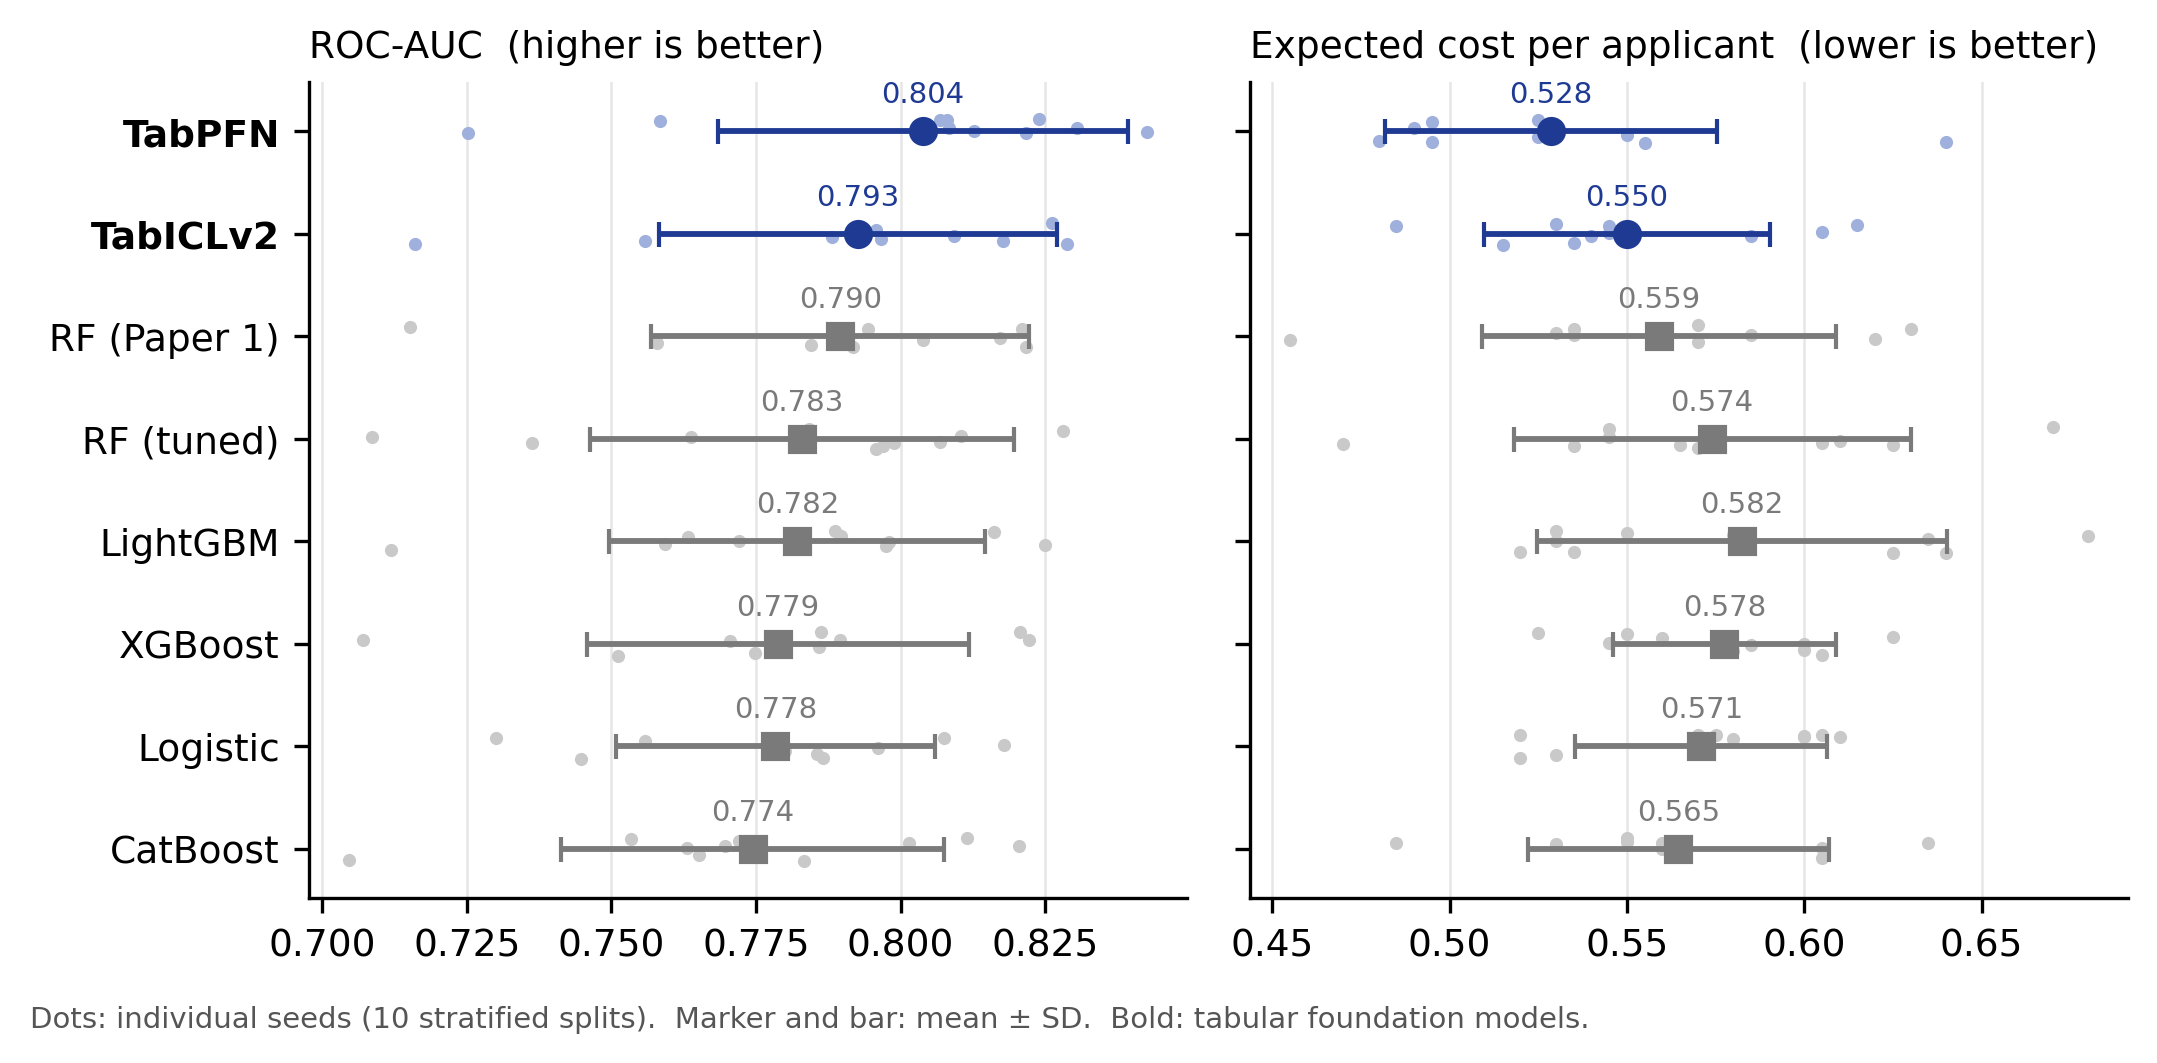

saved /content/drive/MyDrive/credit-tfm-figures/fig_e1_benchmark.pdf


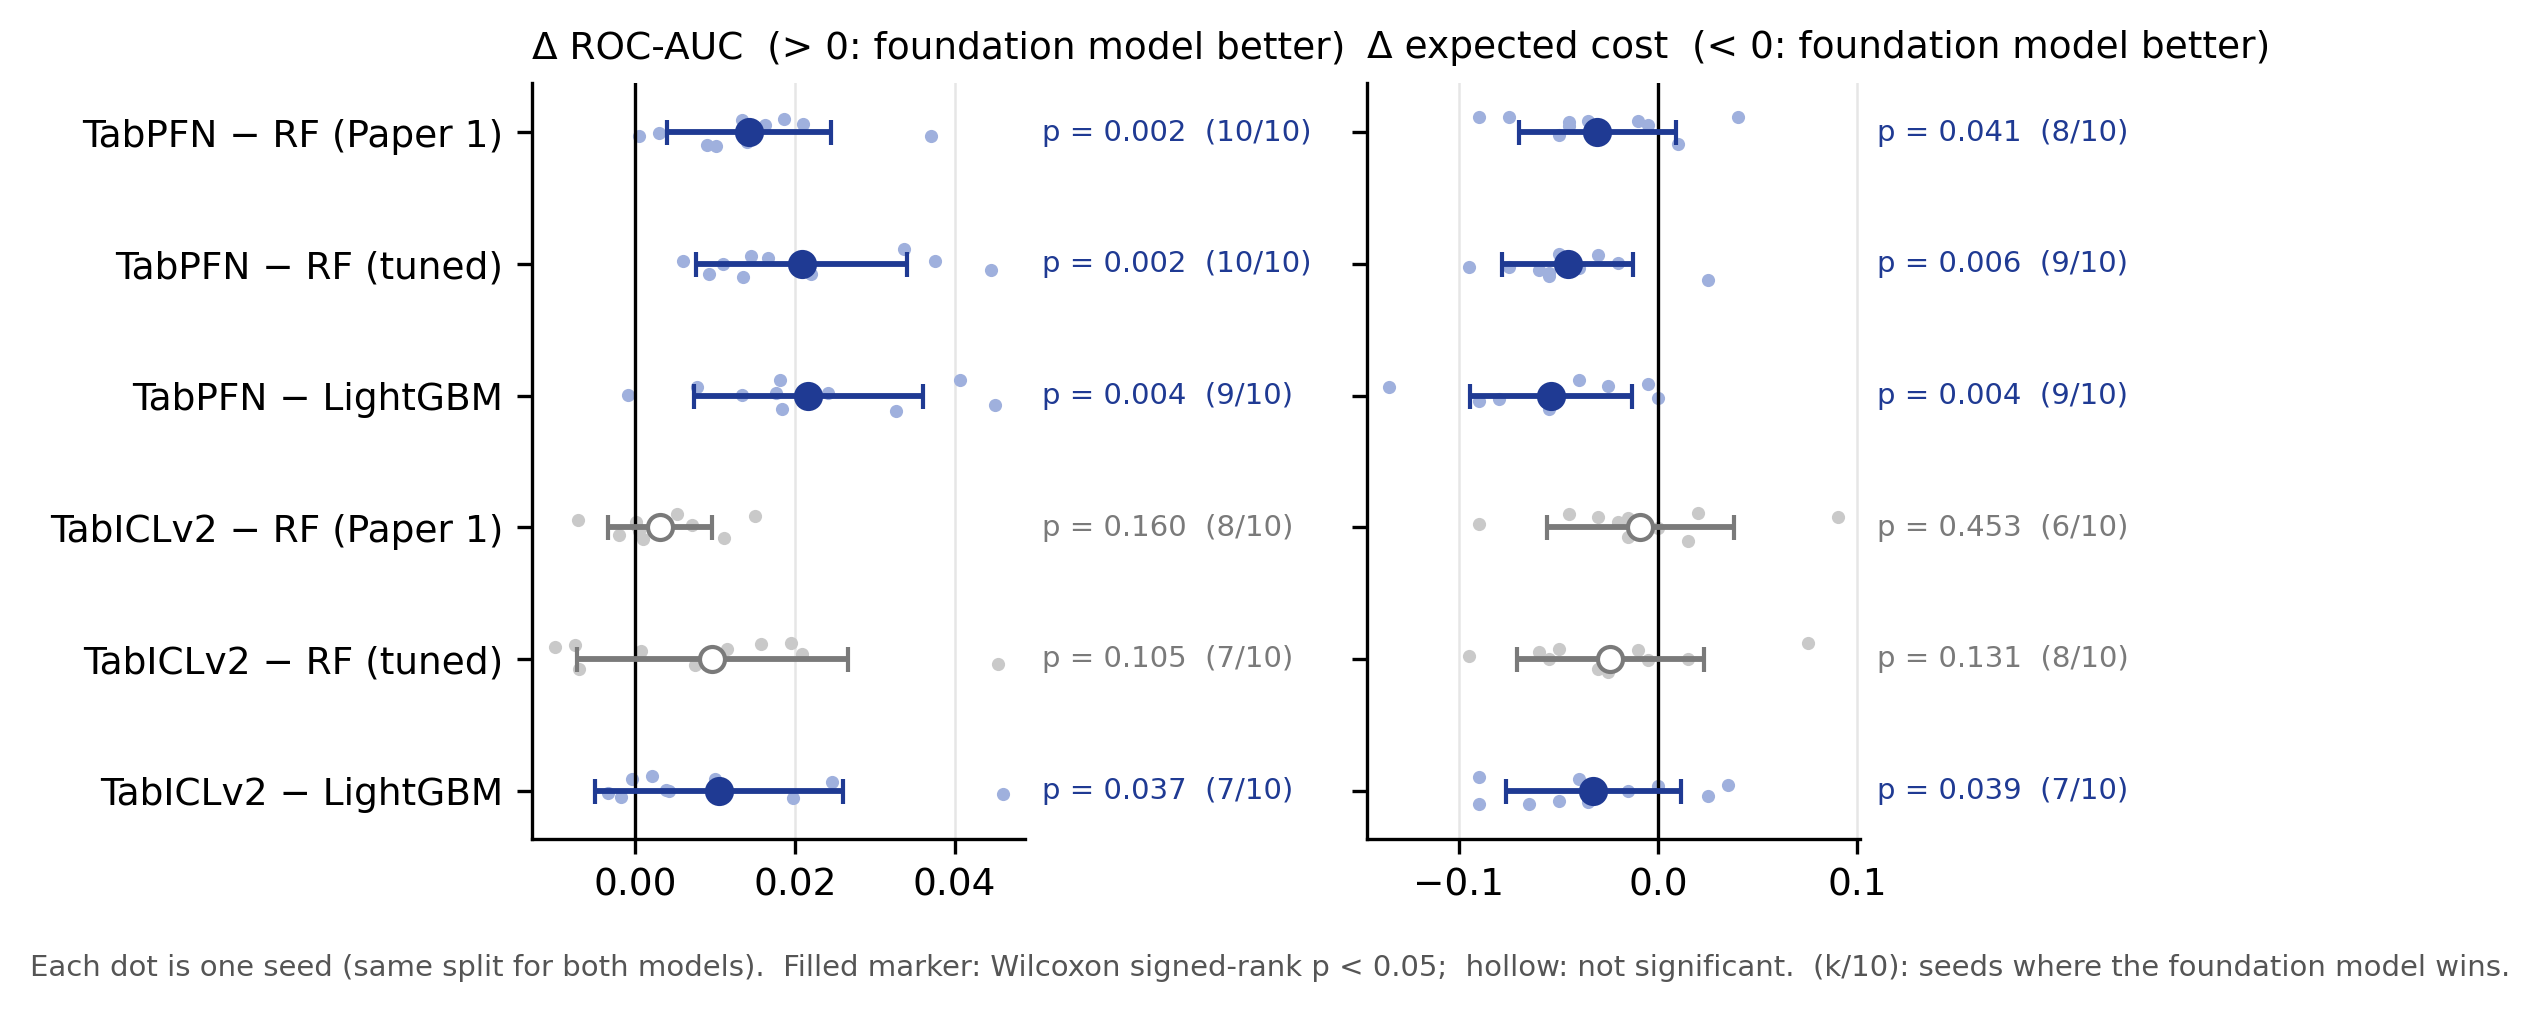

saved /content/drive/MyDrive/credit-tfm-figures/fig_e1_paired.pdf


In [ ]:
# ===== E1 benchmark + paired-difference charts =====
# Paste this WHOLE file into ONE new Colab cell (delete any old code in the cell first).
# Saves PNG + PDF to My Drive/credit-tfm-figures and shows the image below the cell.

import glob
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import Image, display
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

R = Path(os.environ.get("RESULTS_DIR", "/content/drive/MyDrive/credit-tfm-results"))
F = Path(os.environ.get("FIGURES_DIR", "/content/drive/MyDrive/credit-tfm-figures"))
F.mkdir(parents=True, exist_ok=True)

NAMES = {"tabpfn": "TabPFN", "tabicl": "TabICLv2", "rf_paper1": "RF (Paper 1)",
         "rf": "RF (tuned)", "lgbm": "LightGBM", "xgb": "XGBoost",
         "logreg": "Logistic", "catboost": "CatBoost"}
FM = {"tabpfn", "tabicl"}
DARK, GREY, LIGHT = "#1f3a93", "#7a7a7a", "#c9c9c9"
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "savefig.dpi": 300, "legend.frameon": False})

rows = [json.load(open(f)) for f in glob.glob(str(R / "E1" / "seed*" / "*_metrics.json"))]
df = pd.DataFrame(rows)
wide = df.pivot(index="seed", columns="model")
print(f"Loaded {len(rows)} result files, {df['seed'].nunique()} seeds")


def save(fig, name):
    fig.tight_layout()
    for ext in ("pdf", "png"):
        fig.savefig(F / f"{name}.{ext}", bbox_inches="tight")
    plt.close(fig)
    display(Image(filename=str(F / f"{name}.png"), width=900))   # shows it here in Colab
    print("saved", F / f"{name}.pdf")


# ---------------------------------------------------------------- Fig. A
order = df.groupby("model")["roc_auc"].mean().sort_values().index.tolist()
fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.4), sharey=True)
panels = [("roc_auc", "ROC-AUC  (higher is better)"),
          ("exp_cost", "Expected cost per applicant  (lower is better)")]
rng = np.random.default_rng(0)
for ax, (metric, title) in zip(axes, panels):
    for y, m in enumerate(order):
        v = wide[metric][m].to_numpy()
        col = DARK if m in FM else GREY
        ax.scatter(v, y + rng.uniform(-0.12, 0.12, len(v)), s=10, color=LIGHT if m not in FM else "#9fb0dd",
                   zorder=2, linewidths=0)
        ax.errorbar(v.mean(), y, xerr=v.std(ddof=1), fmt="o" if m in FM else "s", color=col,
                    ms=6, capsize=3, lw=1.4, zorder=3)
        ax.annotate(f"{v.mean():.3f}", (v.mean(), y), textcoords="offset points", xytext=(0, 7),
                    ha="center", fontsize=7, color=col)
    ax.set_title(title, fontsize=9, loc="left")
    ax.grid(axis="x", color="#e6e6e6", lw=0.6)
axes[0].set_yticks(range(len(order)), [NAMES.get(m, m) for m in order])
for t in axes[0].get_yticklabels():
    if t.get_text() in ("TabPFN", "TabICLv2"):
        t.set_fontweight("bold")
fig.text(0.01, -0.02, "Dots: individual seeds (10 stratified splits).  Marker and bar: mean ± SD.  "
         "Bold: tabular foundation models.", fontsize=7, color="#555555")
save(fig, "fig_e1_benchmark")

# ---------------------------------------------------------------- Fig. B
pairs = [(fm, b) for fm in ["tabpfn", "tabicl"] for b in ["rf_paper1", "rf", "lgbm"]
         if fm in wide["roc_auc"] and b in wide["roc_auc"]]
fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.2), sharey=True)
for ax, (metric, title, better) in zip(axes, [
        ("roc_auc", "Δ ROC-AUC  (> 0: foundation model better)", 1),
        ("exp_cost", "Δ expected cost  (< 0: foundation model better)", -1)]):
    for y, (fm, b) in enumerate(pairs[::-1]):
        d = (wide[metric][fm] - wide[metric][b]).to_numpy()
        p = wilcoxon(d).pvalue
        sig = p < 0.05
        col = DARK if sig else GREY
        ax.scatter(d, np.full(len(d), y) + rng.uniform(-0.12, 0.12, len(d)), s=10,
                   color="#9fb0dd" if sig else LIGHT, linewidths=0, zorder=2)
        ax.errorbar(d.mean(), y, xerr=d.std(ddof=1), fmt="o", mfc=col if sig else "white",
                    mec=col, color=col, ms=6, capsize=3, lw=1.4, zorder=3)
        wins = int((d * better > 0).sum())
        ax.annotate(f"p = {p:.3f}  ({wins}/10)", (1.0, y), xycoords=("axes fraction", "data"),
                    xytext=(4, 0), textcoords="offset points", va="center", fontsize=7, color=col)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(title, fontsize=9, loc="left")
    ax.grid(axis="x", color="#e6e6e6", lw=0.6)
axes[0].set_yticks(range(len(pairs)),
                   [f"{NAMES[fm]} − {NAMES[b]}" for fm, b in pairs[::-1]])
fig.text(0.01, -0.03, "Each dot is one seed (same split for both models).  Filled marker: Wilcoxon "
         "signed-rank p < 0.05;  hollow: not significant.  (k/10): seeds where the foundation model wins.",
         fontsize=7, color="#555555")
fig.subplots_adjust(wspace=0.55)
save(fig, "fig_e1_paired")

In [ ]:
# E2 + E3 — Conformal deferral and its fairness (RQ2).  Fast (seconds).
!python experiments/run_e2.py
!python experiments/run_e3.py

    model    method  alpha  coverage_mean  deferral_rate_mean  auto_error_mean  auto_exp_cost_mean
 catboost conformal   0.05          0.950               0.592            0.120               0.581
 catboost conformal   0.10          0.907               0.392            0.152               0.712
 catboost conformal   0.20          0.806               0.103            0.215               0.892
 catboost    window    NaN            NaN               0.078            0.219               0.896
     lgbm conformal   0.05          0.948               0.571            0.117               0.570
     lgbm conformal   0.10          0.906               0.352            0.144               0.655
     lgbm conformal   0.20          0.814               0.094            0.205               0.836
     lgbm    window    NaN            NaN               0.066            0.211               0.846
   logreg conformal   0.05          0.948               0.582            0.122               0.552
   logreg 

In [ ]:
import pandas as pd, os
R = os.environ['RESULTS_DIR']
models = ['tabpfn', 'tabicl', 'rf_paper1']
for gv in ['age_band', 'foreign_worker']:
    t = pd.read_csv(f'{R}/E3/{gv}.csv')
    t['group'] = t['group'].astype(str)
    t = t[t['model'].isin(models) & ((t['alpha'] == 0.1) | t['alpha'].isna())]
    print(f'\n===== {gv}: per-group rates (conformal α=0.10 and fixed window) =====')
    print(t[~t['group'].str.startswith('GAP')][['model','method','group','n','deferral_rate',
          'coverage','auto_error','auto_tpr']].round(3).to_string(index=False))
    print(f'\n===== {gv}: gaps between groups, with 95% bootstrap CI =====')
    print(t[t['group'].str.startswith('GAP')][['model','method','group','gap','ci_low','ci_high']]
          .round(3).to_string(index=False))


===== age_band: per-group rates (conformal α=0.10 and fixed window) =====
    model            method   group    n  deferral_rate  coverage  auto_error  auto_tpr
rf_paper1         conformal  25plus 1705          0.311     0.901       0.144     0.225
rf_paper1         conformal under25  295          0.600     0.902       0.246     0.297
rf_paper1 mondrian_age_band  25plus 1705          0.316     0.902       0.143     0.213
rf_paper1 mondrian_age_band under25  295          0.529     0.851       0.317     0.370
rf_paper1            window  25plus 1705          0.082       NaN       0.192     0.336
rf_paper1            window under25  295          0.156       NaN       0.309     0.434
   tabicl         conformal  25plus 1705          0.316     0.902       0.143     0.361
   tabicl         conformal under25  295          0.573     0.905       0.222     0.469
   tabicl mondrian_age_band  25plus 1705          0.337     0.907       0.141     0.349
   tabicl mondrian_age_band under25  295     

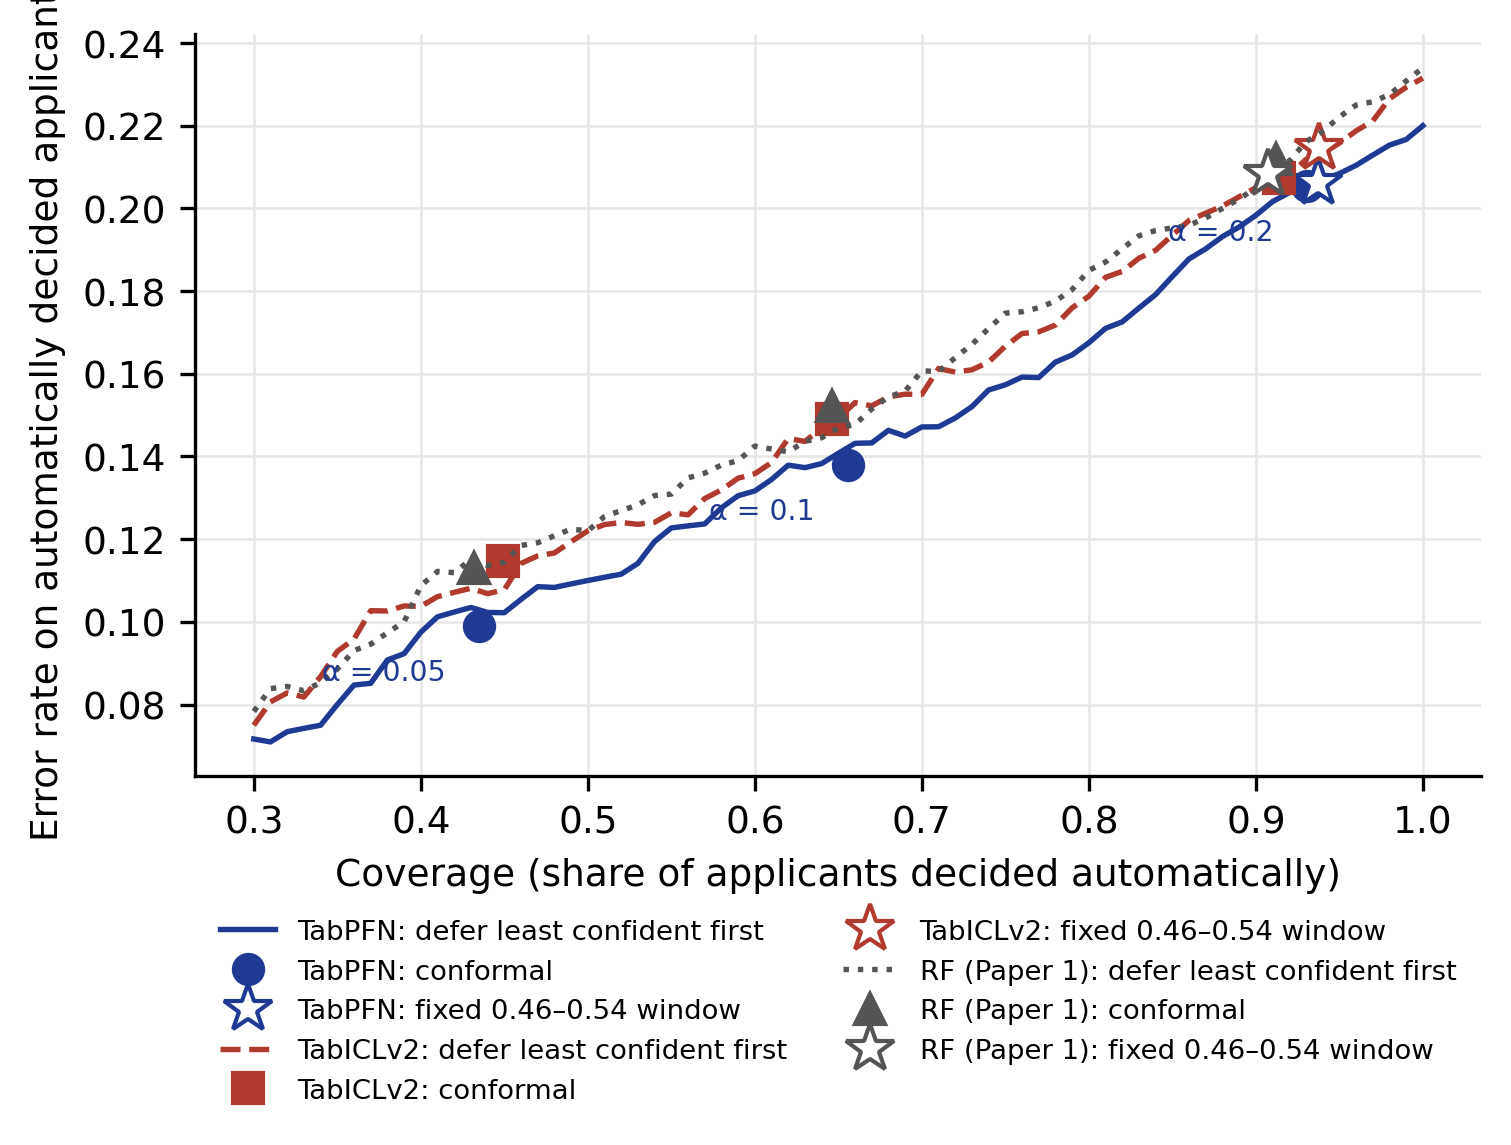

saved /content/drive/MyDrive/credit-tfm-figures/fig_e2_risk_coverage.pdf


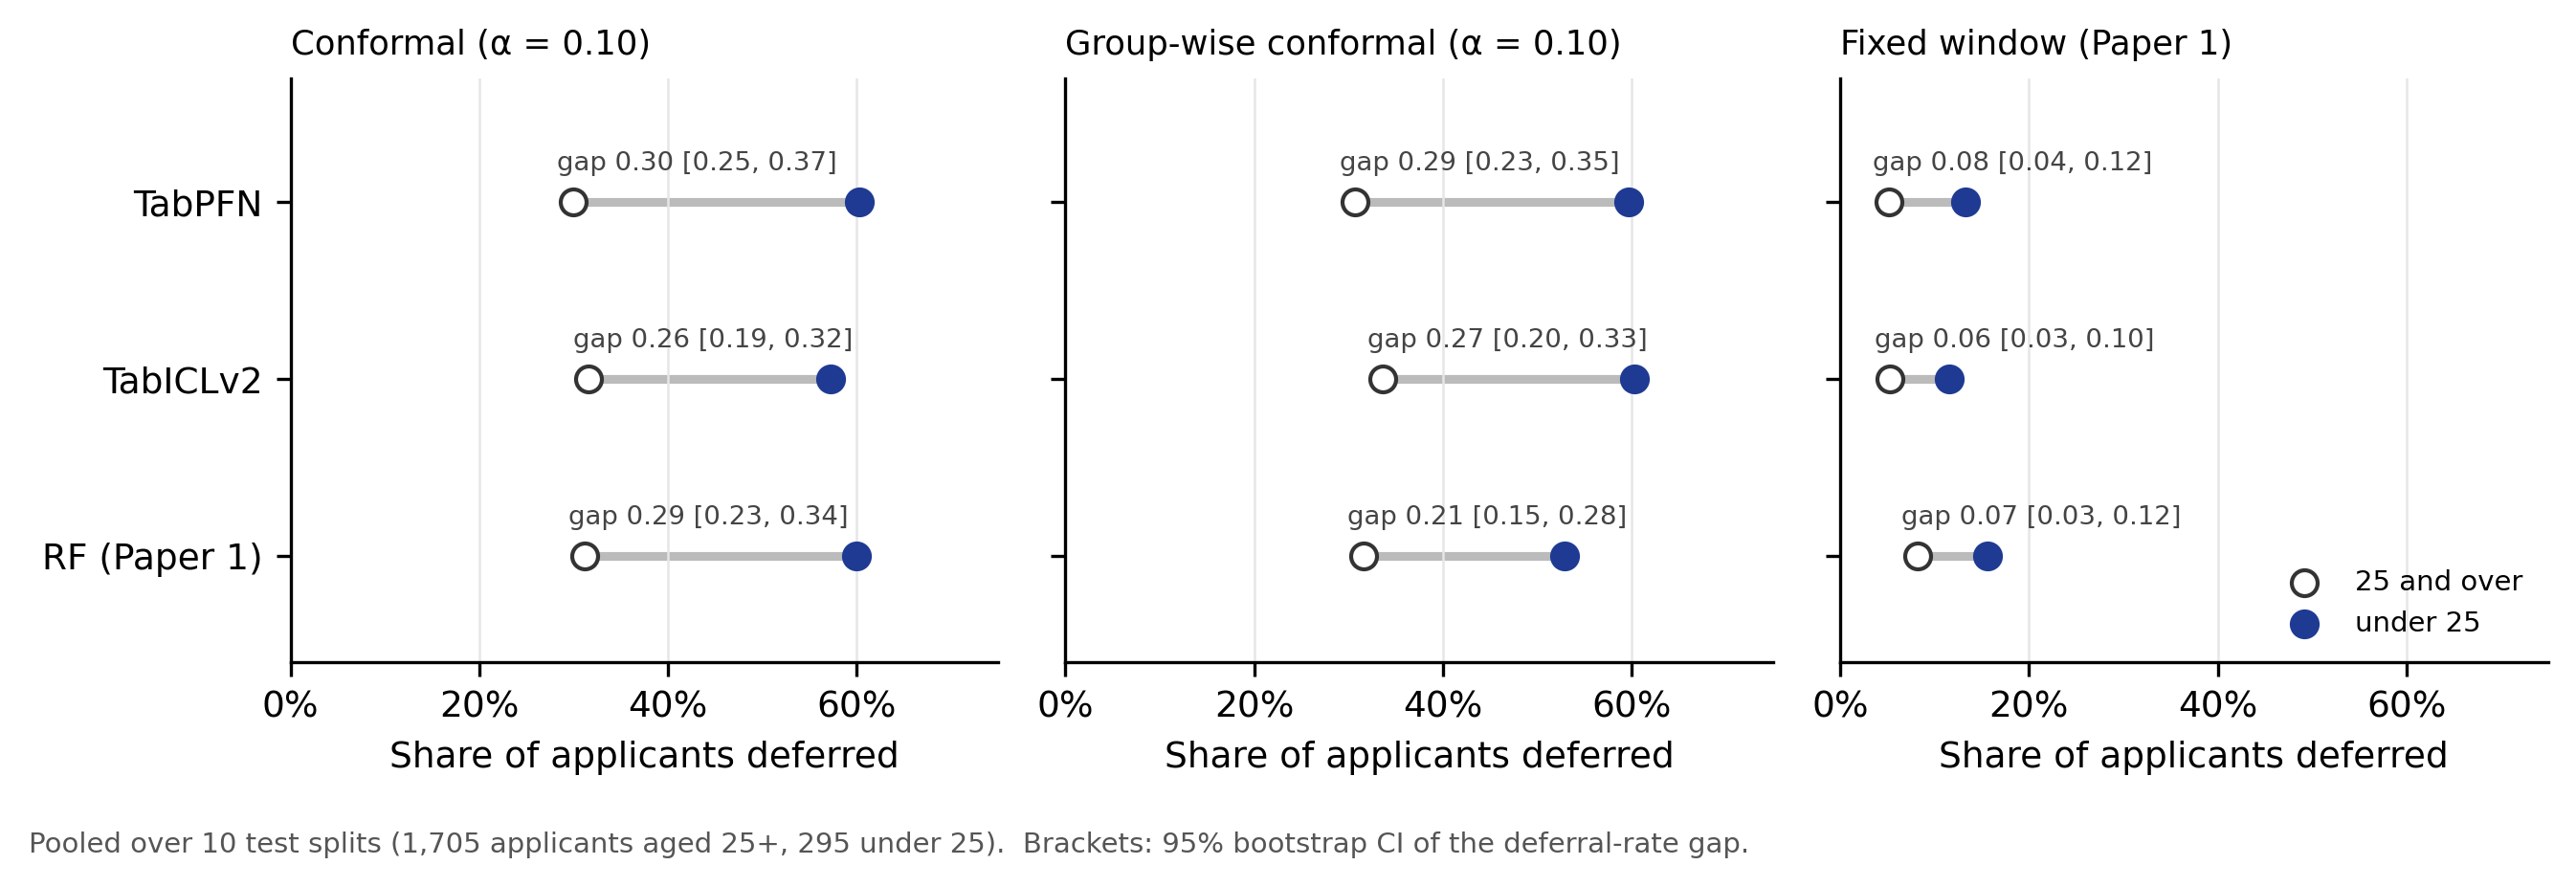

saved /content/drive/MyDrive/credit-tfm-figures/fig_e3_deferral_by_age.pdf


In [ ]:
# ===== E2 risk-coverage + E3 deferral-by-age figures =====

import os, glob
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

R = Path(os.environ.get("RESULTS_DIR", "/content/drive/MyDrive/credit-tfm-results"))
F = Path(os.environ.get("FIGURES_DIR", "/content/drive/MyDrive/credit-tfm-figures"))
F.mkdir(parents=True, exist_ok=True)
NAMES = {"tabpfn": "TabPFN", "tabicl": "TabICLv2", "rf_paper1": "RF (Paper 1)"}
STYLE = {"tabpfn": ("#1f3a93", "o", "-"), "tabicl": ("#b03a2e", "s", "--"), "rf_paper1": ("#555555", "^", ":")}
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "savefig.dpi": 300, "legend.frameon": False})

def save(fig, name, width=820):
    fig.tight_layout()
    for ext in ("pdf", "png"):
        fig.savefig(F / f"{name}.{ext}", bbox_inches="tight")
    plt.close(fig)
    display(Image(filename=str(F / f"{name}.png"), width=width))
    print("saved", F / f"{name}.pdf")

# ---------------------------------------------------------------- Fig. E2: risk-coverage
def risk_coverage(y, p, thr=0.5):
    d = (p >= thr).astype(int)
    conf = np.abs(p - thr)
    order = np.argsort(-conf, kind="stable")
    err = (d[order] != y[order]).astype(float)
    k = np.arange(1, len(y) + 1)
    return k / len(y), np.cumsum(err) / k

e2 = pd.read_csv(R / "E2" / "summary.csv")
grid = np.linspace(0.3, 1.0, 71)
fig, ax = plt.subplots(figsize=(5.2, 4.0))
for m in ["tabpfn", "tabicl", "rf_paper1"]:
    c, mk, ls = STYLE[m]
    curves = []
    for f in sorted(glob.glob(str(R / "E1" / "seed*" / f"{m}_test.csv"))):
        d = pd.read_csv(f)
        cov, risk = risk_coverage(d["y"].to_numpy(), d["p_bad"].to_numpy())
        curves.append(np.interp(grid, cov, risk))
    ax.plot(grid, np.mean(curves, 0), color=c, ls=ls, lw=1.3, label=f"{NAMES[m]}: defer least confident first")
    s = e2[(e2["model"] == m) & (e2["method"] == "conformal")].sort_values("alpha")
    ax.plot(1 - s["deferral_rate_mean"], s["auto_error_mean"], color=c, marker=mk, ls="none", ms=7,
            label=f"{NAMES[m]}: conformal")
    if m == "tabpfn":   # label α once, for TabPFN only, to keep the chart readable
        for _, r in s.iterrows():
            ax.annotate(f"α = {r['alpha']:g}", (1 - r["deferral_rate_mean"], r["auto_error_mean"]),
                        textcoords="offset points", xytext=(-8, -13), fontsize=6.8, color=c, ha="right")
    w = e2[(e2["model"] == m) & (e2["method"] == "window")]
    ax.plot(1 - w["deferral_rate_mean"], w["auto_error_mean"], color=c, marker="*", ms=12, mfc="white",
            ls="none", label=f"{NAMES[m]}: fixed 0.46–0.54 window")
ax.set(xlabel="Coverage (share of applicants decided automatically)",
       ylabel="Error rate on automatically decided applicants")
ax.grid(color="#e6e6e6", lw=0.6)
ax.legend(fontsize=6.6, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2)
save(fig, "fig_e2_risk_coverage")

# ---------------------------------------------------------------- Fig. E3: deferral by age band
t = pd.read_csv(R / "E3" / "age_band.csv")
t["group"] = t["group"].astype(str)
t = t[((t["alpha"] == 0.1) | t["alpha"].isna())]
methods = [("conformal", "Conformal (α = 0.10)"), ("mondrian_age_band", "Group-wise conformal (α = 0.10)"),
           ("window", "Fixed window (Paper 1)")]
models = ["tabpfn", "tabicl", "rf_paper1"]
fig, axes = plt.subplots(1, 3, figsize=(9.0, 2.9), sharey=True)
for ax, (meth, title) in zip(axes, methods):
    for y, m in enumerate(models[::-1]):
        s = t[(t["model"] == m) & (t["method"] == meth)]
        old = s.loc[s["group"] == "25plus", "deferral_rate"].iloc[0]
        young = s.loc[s["group"] == "under25", "deferral_rate"].iloc[0]
        g = s[s["group"] == "GAP_deferral"].iloc[0]
        ax.plot([old, young], [y, y], color="#bbbbbb", lw=2.2, zorder=1)
        ax.scatter([old], [y], s=42, marker="o", facecolor="white", edgecolor="#333333", zorder=2,
                   label="25 and over" if y == 0 else None)
        ax.scatter([young], [y], s=42, marker="o", color="#1f3a93", zorder=3,
                   label="under 25" if y == 0 else None)
        ax.annotate(f"gap {g['gap']:.2f} [{g['ci_low']:.2f}, {g['ci_high']:.2f}]", (old, y),
                    textcoords="offset points", xytext=(-4, 8), ha="left", fontsize=6.6, color="#444444")
    ax.set_title(title, fontsize=8.5, loc="left")
    ax.set_xlim(0, 0.75)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.grid(axis="x", color="#e6e6e6", lw=0.6)
    ax.set_xlabel("Share of applicants deferred")
axes[0].set_yticks(range(len(models)), [NAMES[m] for m in models[::-1]])
axes[0].set_ylim(-0.6, len(models) - 0.3)
axes[-1].legend(loc="lower right", fontsize=7)
fig.text(0.01, -0.04, "Pooled over 10 test splits (1,705 applicants aged 25+, 295 under 25).  "
         "Brackets: 95% bootstrap CI of the deferral-rate gap.", fontsize=7, color="#555555")
save(fig, "fig_e3_deferral_by_age", width=900)

In [ ]:
from google.colab import files
import shutil, os
up = files.upload()
for n in up:
    clean = 'explain.py' if 'explain' in n else 'pipeline.py' if 'pipeline' in n else 'default.yaml'
    folder = 'configs' if clean.endswith('.yaml') else 'src'
    shutil.move(n, f'{folder}/{clean}')
    shutil.copy(f'{folder}/{clean}', f'/content/drive/MyDrive/credit-tfm/credit-tfm/{folder}/{clean}')
    print('updated', folder + '/' + clean)

Saving default.yaml to default.yaml
Saving pipeline.py to pipeline.py
Saving explain.py to explain.py
updated configs/default.yaml
updated src/pipeline.py
updated src/explain.py


In [ ]:
import os
from google.colab import userdata
os.environ['TABPFN_TOKEN'] = userdata.get('TABPFN_TOKEN')
!python experiments/run_e4.py --seeds 0

04:47:40 E4 tabicl: smallest budget with mean top-3 agreement >= 0.9: 128
04:47:40 E4 tabpfn: smallest budget with mean top-3 agreement >= 0.9: 256
 model  budget  spearman_mean  top3_jaccard_mean  top3pos_jaccard_mean  batch_ms_per_applicant_mean  spearman_std  top3_jaccard_std  top3pos_jaccard_std  batch_ms_per_applicant_std  single_applicant_ms_median
tabicl      32          0.673              0.402                 0.425                      110.466           NaN               NaN                  NaN                         NaN                    9242.083
tabicl      64          0.908              0.804                 0.776                      222.818           NaN               NaN                  NaN                         NaN                   18741.131
tabicl     128          0.960              0.902                 0.889                      452.173           NaN               NaN                  NaN                         NaN                   38156.112
tabicl     256  

In [ ]:
from google.colab import files
import shutil, os
up = files.upload()
for n in up:
    clean = 'explain.py' if 'explain' in n else 'pipeline.py' if 'pipeline' in n else 'default.yaml'
    folder = 'configs' if clean.endswith('.yaml') else 'src'
    shutil.move(n, f'{folder}/{clean}')
    shutil.copy(f'{folder}/{clean}', f'/content/drive/MyDrive/credit-tfm/credit-tfm/{folder}/{clean}')
    print('updated', folder + '/' + clean)

Saving default (1).yaml to default (1).yaml
Saving pipeline (1).py to pipeline (1).py
updated configs/default.yaml
updated src/pipeline.py


In [ ]:
#E5 - The Headline experiment
import os
from google.colab import userdata
os.environ['TABPFN_TOKEN'] = userdata.get('TABPFN_TOKEN')
!python experiments/run_e5.py --seeds 0

[data] ucimlrepo failed ("South German Credit" dataset (id=573) exists in the repository, but is not avai); falling back to the UCI zip
10:06:21 E5 seed 0 tabicl context size 200
INFO: You are downloading 'tabicl-classifier-v2-20260212.ckpt', the latest best-performing version, used in our TabICLv2 paper.

Checkpoint 'tabicl-classifier-v2-20260212.ckpt' not cached.


tabicl-classifier-v2-20260212.ckpt: downloading bytes:  75% 83.0M/110M [00:00<00:00, 127MB/s, 6.32MB/s  ]
tabicl-classifier-v2-20260212.ckpt: downloading bytes: 100% 104M/104M [00:01<00:00, 79.8MB/s, 9.90MB/s  ]
tabicl-classifier-v2-20260212.ckpt: reconstructing file: 100% 110M/110M [00:01<00:00, 84.5MB/s, 10.7MB/s  ]
10:07:03     tabicl size 200: resample 1/5 done (42 s)
10:07:42     tabicl size 200: resample 2/5 done (40 s)
10:08:21     tabicl size 200: resample 3/5 done (39 s)
10:09:01     tabicl size 200: resample 4/5 done (40 s)
10:09:41     tabicl size 200: resample 5/5 done (40 s)
10:09:42 E5 seed 0 tabicl context s

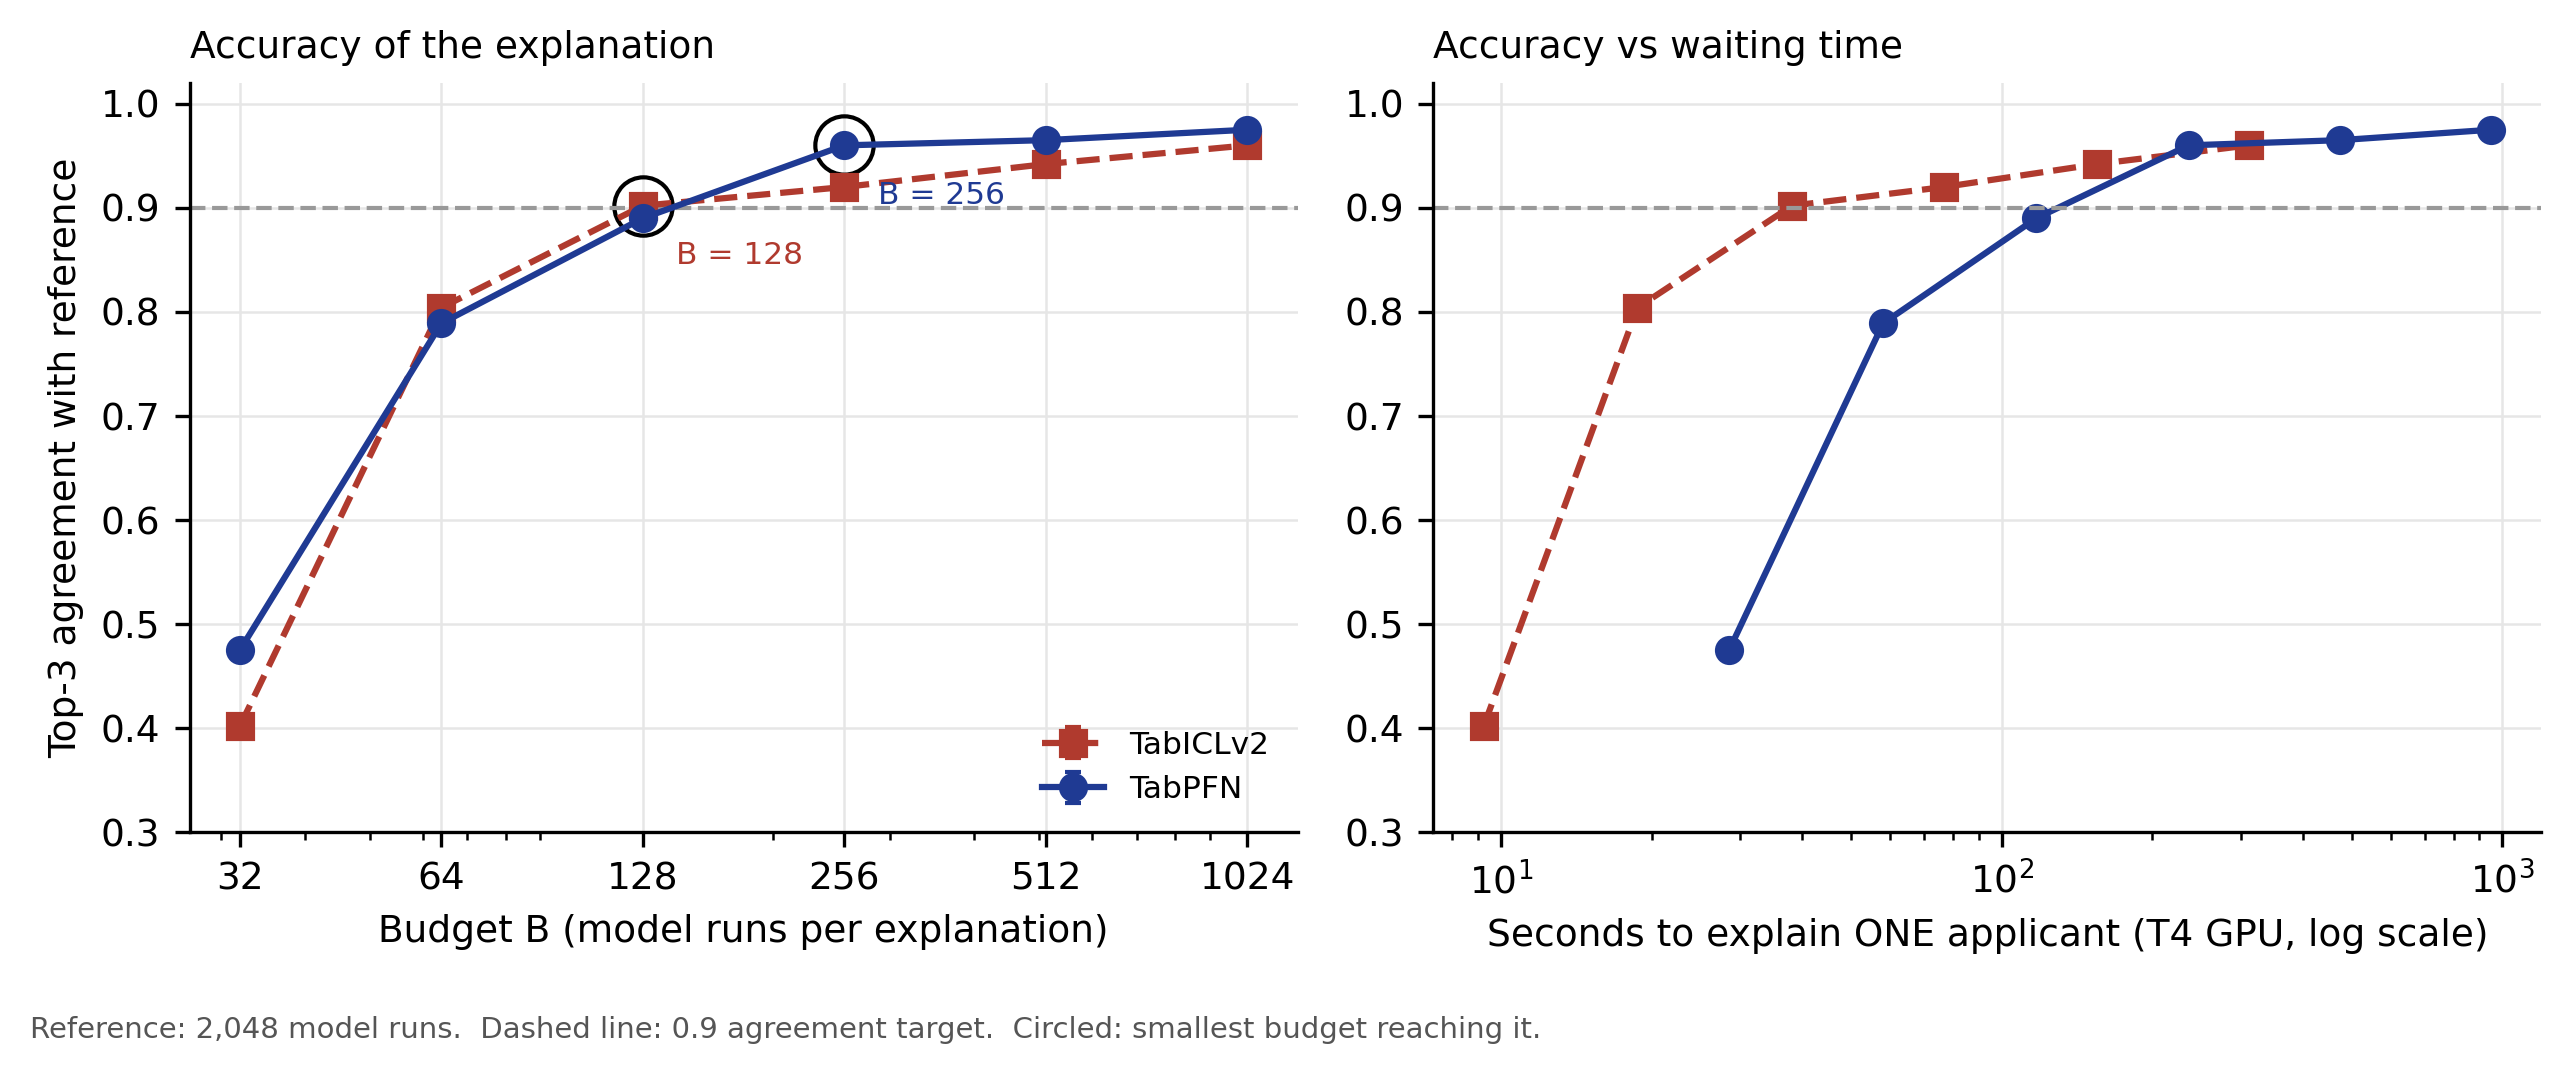

saved /content/drive/MyDrive/credit-tfm-figures/fig_e4_budget_vs_time.pdf


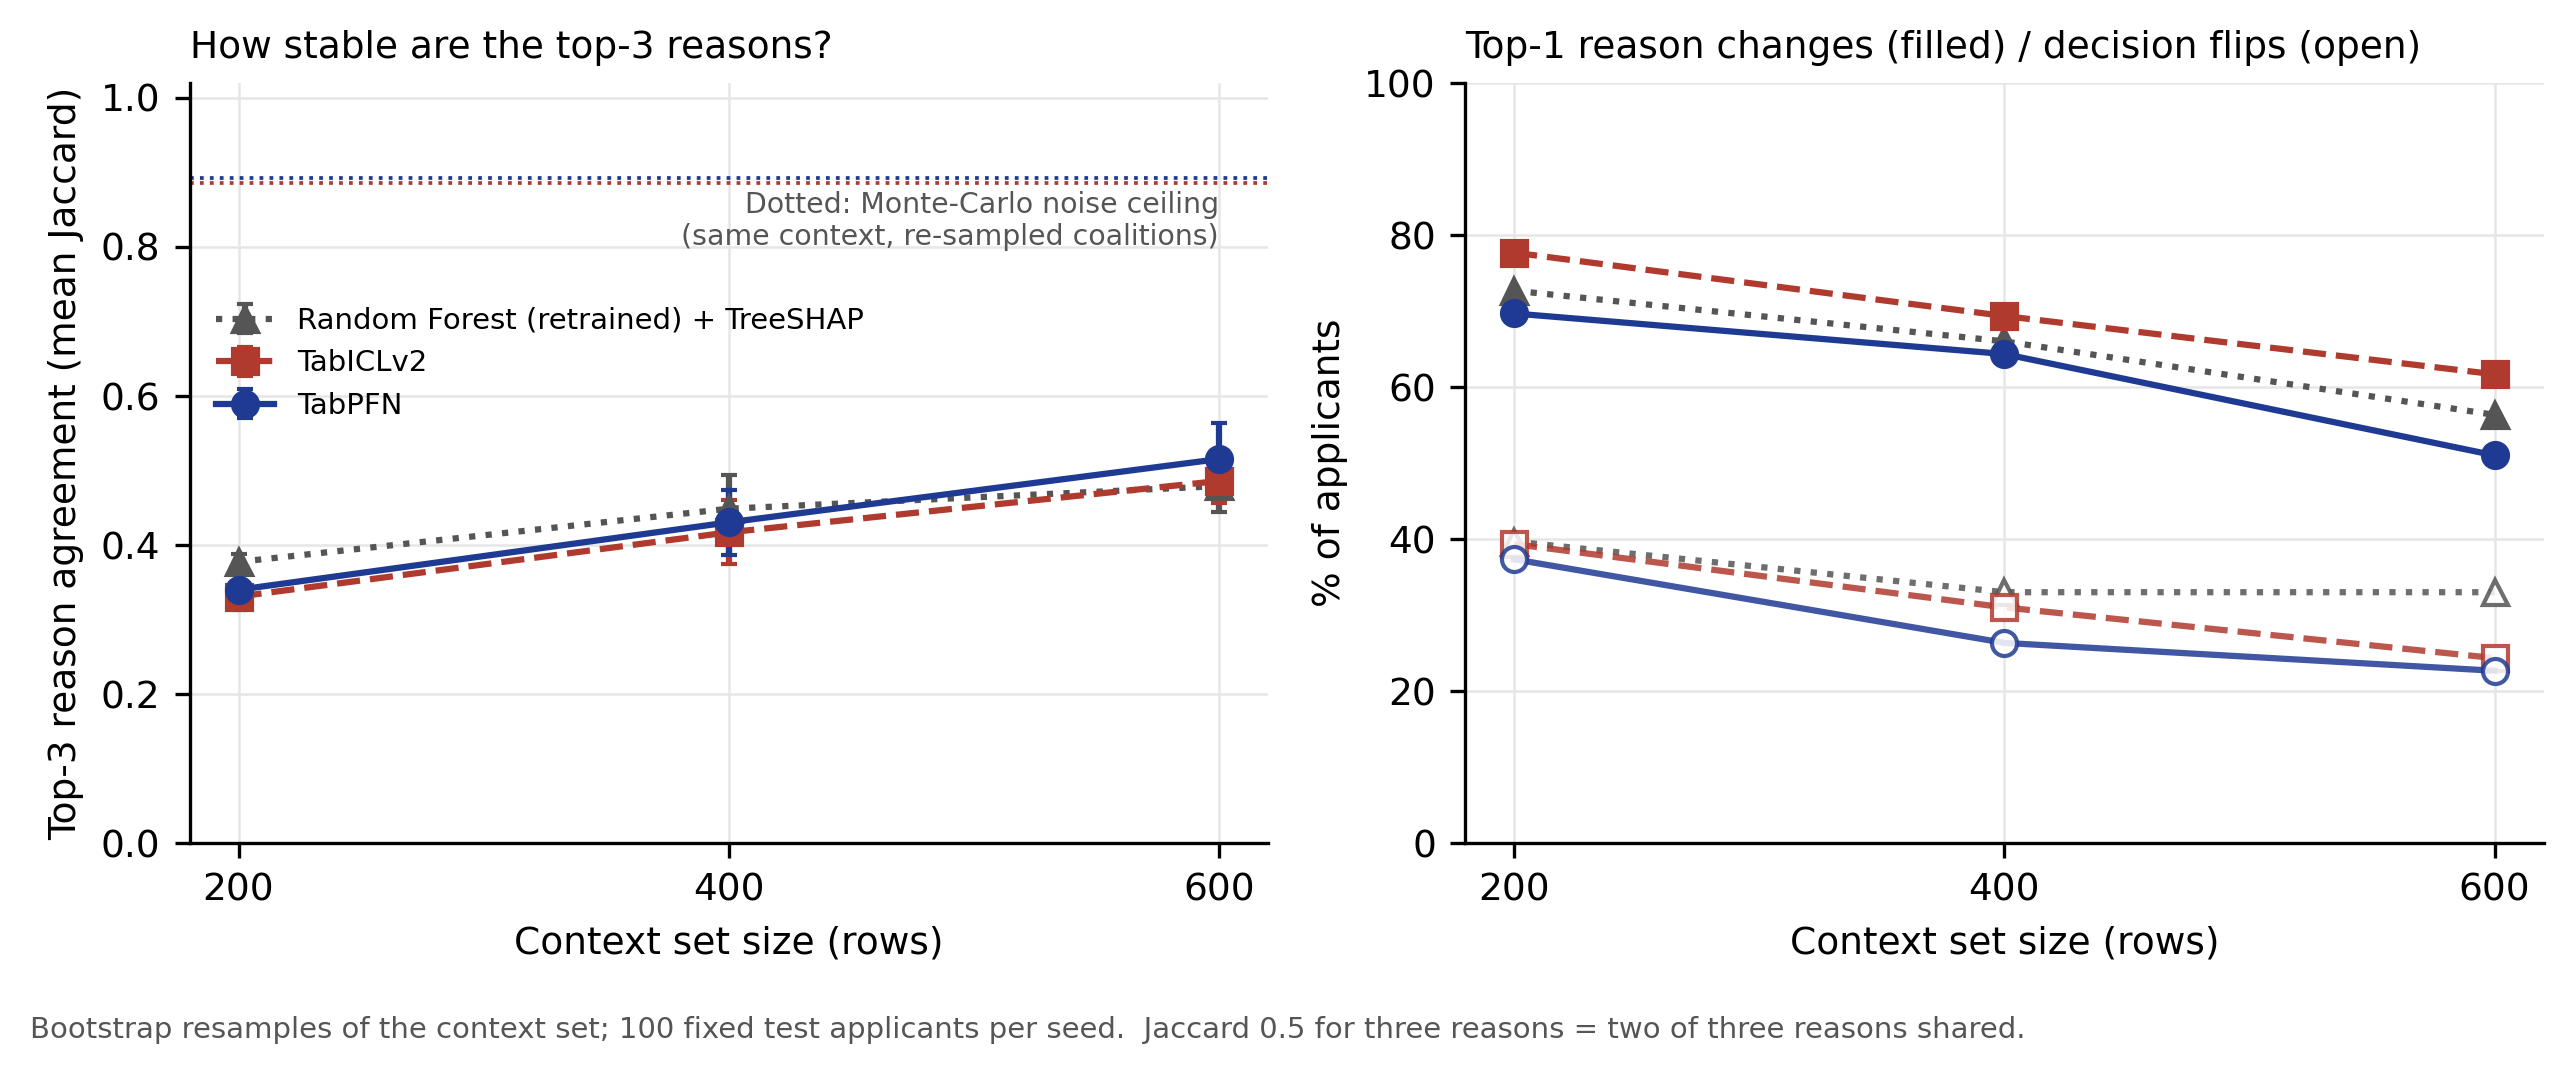

saved /content/drive/MyDrive/credit-tfm-figures/fig_e5_stability.pdf


In [ ]:
# ===== E4 explanation speed + E5 explanation stability figures =====
# Paste this WHOLE file into ONE new Colab cell (after cell 1 has mounted Drive).
# Shows both figures below the cell and saves PNG + PDF to My Drive/credit-tfm-figures.
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

R = Path(os.environ.get("RESULTS_DIR", "/content/drive/MyDrive/credit-tfm-results"))
F = Path(os.environ.get("FIGURES_DIR", "/content/drive/MyDrive/credit-tfm-figures"))
F.mkdir(parents=True, exist_ok=True)
NAMES = {"tabpfn": "TabPFN", "tabicl": "TabICLv2", "rf": "Random Forest (retrained) + TreeSHAP"}
STYLE = {"tabpfn": ("#1f3a93", "o", "-"), "tabicl": ("#b03a2e", "s", "--"), "rf": ("#555555", "^", ":")}
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "savefig.dpi": 300, "legend.frameon": False})

def save(fig, name, width=820):
    fig.tight_layout()
    for ext in ("pdf", "png"):
        fig.savefig(F / f"{name}.{ext}", bbox_inches="tight")
    plt.close(fig)
    display(Image(filename=str(F / f"{name}.png"), width=width))
    print("saved", F / f"{name}.pdf")

# ---------------------------------------------------------------- E4: agreement vs budget and vs time
e4 = pd.read_csv(R / "E4" / "summary.csv")
fig, axes = plt.subplots(1, 2, figsize=(8.6, 3.4))
for m, d in e4.groupby("model"):
    d = d.sort_values("budget")
    c, mk, ls = STYLE.get(m, ("#333333", "o", "-"))
    err = d["top3_jaccard_std"].fillna(0)
    axes[0].errorbar(d["budget"], d["top3_jaccard_mean"], yerr=err, color=c, marker=mk, ls=ls, capsize=2, label=NAMES.get(m, m))
    ok = d[d["top3_jaccard_mean"] >= 0.9]
    if len(ok):
        r = ok.iloc[0]
        axes[0].plot(r["budget"], r["top3_jaccard_mean"], marker="o", ms=14, mfc="none", mec="black", ls="none")
        axes[0].annotate(f"B = {int(r['budget'])}", (r["budget"], r["top3_jaccard_mean"]), textcoords="offset points",
                         xytext=(8, -14), fontsize=7.5, color=c)
    if "single_applicant_ms_median" in d:
        axes[1].plot(d["single_applicant_ms_median"] / 1000, d["top3_jaccard_mean"], color=c, marker=mk, ls=ls, label=NAMES.get(m, m))
for ax in axes:
    ax.axhline(0.9, color="#999999", lw=1, ls="--")
    ax.set_xscale("log"); ax.set_ylim(0.3, 1.02); ax.grid(color="#e6e6e6", lw=0.6)
axes[0].set_xticks([32, 64, 128, 256, 512, 1024], ["32", "64", "128", "256", "512", "1024"])
axes[0].set(xlabel="Budget B (model runs per explanation)", ylabel="Top-3 agreement with reference")
axes[0].set_title("Accuracy of the explanation", fontsize=9, loc="left")
axes[1].set(xlabel="Seconds to explain ONE applicant (T4 GPU, log scale)")
axes[1].set_title("Accuracy vs waiting time", fontsize=9, loc="left")
axes[0].legend(fontsize=7.5, loc="lower right")
fig.text(0.01, -0.03, "Reference: 2,048 model runs.  Dashed line: 0.9 agreement target.  Circled: smallest budget reaching it.",
         fontsize=7, color="#555555")
save(fig, "fig_e4_budget_vs_time")

# ---------------------------------------------------------------- E5: stability vs context size
e5 = pd.read_csv(R / "E5" / "summary.csv")
e5["context_size"] = e5["context_size"].astype(str)
fig, axes = plt.subplots(1, 2, figsize=(8.6, 3.4))
for m, d in e5.groupby("model"):
    c, mk, ls = STYLE.get(m, ("#333333", "o", "-"))
    dd = d[d["context_size"].str.isdigit()].copy()
    dd["n"] = dd["context_size"].astype(int); dd = dd.sort_values("n")
    axes[0].errorbar(dd["n"], dd["top3_jaccard_mean"], yerr=dd["top3_jaccard_std"].fillna(0), color=c, marker=mk, ls=ls,
                     capsize=2, label=NAMES.get(m, m))
    nf = d[d["context_size"] == "noise_floor"]
    if len(nf):
        axes[0].axhline(nf["top3_jaccard_mean"].iloc[0], color=c, lw=0.9, ls=":")
    axes[1].plot(dd["n"], 100 * dd["top1_changed_mean"], color=c, marker=mk, ls=ls, label=f"{NAMES.get(m, m)}: top-1 reason changes")
    axes[1].plot(dd["n"], 100 * dd["decision_flipped_mean"], color=c, marker=mk, ls=ls, mfc="white", alpha=0.85,
                 label=f"{NAMES.get(m, m)}: decision flips")
axes[0].text(600, 0.875, "Dotted: Monte-Carlo noise ceiling\n(same context, re-sampled coalitions)", fontsize=6.8, color="#555555", va="top", ha="right")
axes[0].set(xlabel="Context set size (rows)", ylabel="Top-3 reason agreement (mean Jaccard)", ylim=(0, 1.02), xticks=[200, 400, 600])
axes[0].set_title("How stable are the top-3 reasons?", fontsize=9, loc="left")
axes[0].legend(fontsize=7, loc="upper left", bbox_to_anchor=(0.0, 0.74))
axes[1].set(xlabel="Context set size (rows)", ylabel="% of applicants", ylim=(0, 100), xticks=[200, 400, 600])
axes[1].set_title("Top-1 reason changes (filled) / decision flips (open)", fontsize=9, loc="left")
for ax in axes: ax.grid(color="#e6e6e6", lw=0.6)
fig.text(0.01, -0.03, "Bootstrap resamples of the context set; 100 fixed test applicants per seed.  "
         "Jaccard 0.5 for three reasons = two of three reasons shared.", fontsize=7, color="#555555")
save(fig, "fig_e5_stability")

In [ ]:
import os
from google.colab import userdata
if not os.path.exists('/content/credit-tfm'):
    raise SystemExit('Run cell 1 (Mount Drive) first, then cells 2 and 3.')
os.chdir('/content/credit-tfm')
os.environ['RESULTS_DIR'] = '/content/drive/MyDrive/credit-tfm-results'
os.environ['FIGURES_DIR'] = '/content/drive/MyDrive/credit-tfm-figures'
os.environ['TABPFN_TOKEN'] = userdata.get('TABPFN_TOKEN')
!python experiments/run_e5.py --seeds 0 1 2

[data] ucimlrepo failed ("South German Credit" dataset (id=573) exists in the repository, but is not avai); falling back to the UCI zip
13:25:46 E5 seed 1 tabicl context size 200
INFO: You are downloading 'tabicl-classifier-v2-20260212.ckpt', the latest best-performing version, used in our TabICLv2 paper.

Checkpoint 'tabicl-classifier-v2-20260212.ckpt' not cached.


tabicl-classifier-v2-20260212.ckpt: downloading bytes:  94% 104M/110M [00:02<00:00, 65.7MB/s, 8.62MB/s  ] 
tabicl-classifier-v2-20260212.ckpt: downloading bytes: 100% 104M/104M [00:03<00:00, 32.8MB/s, 9.48MB/s  ]
tabicl-classifier-v2-20260212.ckpt: reconstructing file: 100% 110M/110M [00:03<00:00, 34.8MB/s, 10.2MB/s  ]
13:26:32     tabicl size 200: resample 1/5 done (45 s)
13:27:10     tabicl size 200: resample 2/5 done (39 s)
13:27:50     tabicl size 200: resample 3/5 done (40 s)
13:28:31     tabicl size 200: resample 4/5 done (41 s)
13:29:11     tabicl size 200: resample 5/5 done (40 s)
13:29:12 E5 seed 1 tabicl context 

In [ ]:
# E6 — Gate ablation
import os, yaml
from google.colab import userdata
os.chdir('/content/credit-tfm')
os.environ['RESULTS_DIR'] = '/content/drive/MyDrive/credit-tfm-results'
os.environ['TABPFN_TOKEN'] = userdata.get('TABPFN_TOKEN')
p = 'configs/default.yaml'; c = yaml.safe_load(open(p)); c['e6_seeds'] = [0, 1, 2]
yaml.safe_dump(c, open(p, 'w'), sort_keys=False)
!python experiments/run_e6.py

[data] ucimlrepo failed ("South German Credit" dataset (id=573) exists in the repository, but is not avai); falling back to the UCI zip
11:39:17 E6 seed 0 tabicl
INFO: You are downloading 'tabicl-classifier-v2-20260212.ckpt', the latest best-performing version, used in our TabICLv2 paper.

Checkpoint 'tabicl-classifier-v2-20260212.ckpt' not cached.


tabicl-classifier-v2-20260212.ckpt: downloading bytes:  78% 86.3M/110M [00:01<00:00, 95.8MB/s, 6.48MB/s  ]
tabicl-classifier-v2-20260212.ckpt: downloading bytes: 100% 104M/104M [00:02<00:00, 43.6MB/s, 9.65MB/s  ]
tabicl-classifier-v2-20260212.ckpt: reconstructing file: 100% 110M/110M [00:02<00:00, 46.1MB/s, 10.5MB/s  ]
11:48:50 E6 seed 0 tabpfn

tabpfn-v3.5-20260909.safetensors: downloading bytes:  54% 471M/876M [00:02<00:01, 241MB/s, 40.2MB/s  ]
tabpfn-v3.5-20260909.safetensors: downloading bytes:  64% 560M/876M [00:03<00:01, 230MB/s, 47.0MB/s  ]
tabpfn-v3.5-20260909.safetensors: downloading bytes:  85% 748M/876M [00:03<00:00, 323MB/s, 60

In [ ]:
# milder e5 test
# ===== Milder E5: set-up (no upload needed) =====
# Paste this WHOLE file into ONE Colab cell and run it once (after cells 1-3).
# It (1) adds the small changes to src/pipeline.py, (2) creates experiments/run_e5_mild.py,
# (3) saves copies to your Drive folder, and (4) runs the milder E5 test (~30 min).
import os, shutil
from google.colab import userdata
os.chdir('/content/credit-tfm')
os.environ['RESULTS_DIR'] = '/content/drive/MyDrive/credit-tfm-results'
os.environ['TABPFN_TOKEN'] = userdata.get('TABPFN_TOKEN')

p = 'src/pipeline.py'
s = open(p).read()
if 'out_name="E5"' not in s:
    s = s.replace('def run_e5(cfg, base: Path | None = None, models=None):\n    data = load_dataset(cfg["dataset"])\n    e1, root = _root("E1", base), _root("E5", base)',
                  'def run_e5(cfg, base: Path | None = None, models=None, out_name="E5"):\n    data = load_dataset(cfg["dataset"])\n    e1, root = _root("E1", base), _root(out_name, base)', 1)
    s = s.replace('            if is_fm:  # Monte-Carlo noise floor: same full context, two coalition draws',
                  '            if is_fm and cfg.get("e5_noise_floor", True):  # Monte-Carlo noise floor', 1)
    s = s.replace('    return summarise_e5(cfg, base)\n\n\ndef summarise_e5(cfg, base=None):\n    root = _root("E5", base)',
                  '    return summarise_e5(cfg, base, out_name)\n\n\ndef summarise_e5(cfg, base=None, out_name="E5"):\n    root = _root(out_name, base)', 1)
    assert s.count('out_name') >= 4, 'pipeline.py did not match - send Claude a screenshot of this error'
    open(p, 'w').write(s)
    print('pipeline.py updated')
else:
    print('pipeline.py already up to date')

open('experiments/run_e5_mild.py', 'w').write('''"""E5 (milder): each context keeps a random 90% of the 600 rows. Seed 0, ~30 min."""
import argparse, sys
from pathlib import Path
sys.path.insert(0, str(Path(__file__).resolve().parents[1]))
from src.common import load_cfg
from src.pipeline import run_e5
ap = argparse.ArgumentParser(); ap.add_argument("--seeds", type=int, nargs="*", default=[0])
args = ap.parse_args()
cfg = load_cfg()
cfg.update(e5_seeds=args.seeds, context_sizes=[0.9], resample="subsample", e5_noise_floor=False)
run_e5(cfg, out_name="E5_mild")
''')
print('run_e5_mild.py created')

drive_code = '/content/drive/MyDrive/credit-tfm/credit-tfm'
for f in ['src/pipeline.py', 'experiments/run_e5_mild.py']:
    if os.path.isdir(drive_code):
        shutil.copy(f, f'{drive_code}/{f}')
print('copies saved to Drive')

!python experiments/run_e5_mild.py

pipeline.py updated
run_e5_mild.py created
copies saved to Drive
[data] ucimlrepo failed ("South German Credit" dataset (id=573) exists in the repository, but is not avai); falling back to the UCI zip
16:48:18 E5 seed 0 tabicl context size 0.9
INFO: You are downloading 'tabicl-classifier-v2-20260212.ckpt', the latest best-performing version, used in our TabICLv2 paper.

Checkpoint 'tabicl-classifier-v2-20260212.ckpt' not cached.


tabicl-classifier-v2-20260212.ckpt: downloading bytes:  92% 102M/110M [00:01<00:00, 115MB/s, 8.36MB/s  ]  
tabicl-classifier-v2-20260212.ckpt: downloading bytes: 100% 104M/104M [00:01<00:00, 69.3MB/s, 9.82MB/s  ]
tabicl-classifier-v2-20260212.ckpt: reconstructing file: 100% 110M/110M [00:01<00:00, 73.4MB/s, 10.7MB/s  ]
16:49:35     tabicl size 0.9: resample 1/5 done (76 s)
16:50:49     tabicl size 0.9: resample 2/5 done (75 s)
16:52:06     tabicl size 0.9: resample 3/5 done (77 s)
16:53:25     tabicl size 0.9: resample 4/5 done (79 s)
16:54:44     tabicl size

In [ ]:
# E7 — Scaling check on Taiwan credit-card default (drop this first if time is short)
!python experiments/run_e7.py

In [ ]:
# Freeze package versions for the paper
!pip freeze > {os.environ['RESULTS_DIR']}/requirements.lock